
# Bank Marketing Campaign Analysis

**Project Domain:** Banking & Financial Services  
**Analysis Type:** Exploratory Data Analysis (EDA)  
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, SQL and Power BI

---

## 1. Business Understanding

### 1.1 Business Problem

Banks conduct direct marketing campaigns to promote financial products such as term deposits. These campaigns involve contacting potential customers through different communication channels.

However, not every customer responds positively to these campaigns. Understanding customer behaviour, campaign contact frequency, and previous campaign interactions can help banks evaluate campaign effectiveness and identify opportunities to improve their marketing strategies.

The objective of this project is to evaluate the effectiveness of a bank's direct marketing campaign and understand the factors associated with customer subscription to term deposits.

### 1.2 Business Objectives

- Evaluate the overall effectiveness of the marketing campaign.
- Understand customer characteristics associated with subscription.
- Investigate the relationship between contact frequency and subscription rates.
- Examine the influence of previous campaign outcomes.
- Identify customer segments with different subscription patterns.
- Develop data-driven recommendations for improving campaign effectiveness.

### 1.3 Analytical Scope

The project focuses on descriptive and exploratory analysis of customer demographics, financial characteristics, campaign interactions, and subscription outcomes.

The analysis aims to identify associations and patterns within the available dataset. It does not establish causal relationships between customer characteristics and subscription decisions.


## 2. Libraries and Configuration

In [24]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display configuration
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

sns.set_theme(style='whitegrid', context='notebook')

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11

## 3. Data Loading and Understanding

This section introduces the dataset, examines its structure, and evaluates the available variables before proceeding with data quality assessment and preparation.

In [25]:
df = pd.read_csv(r'C:\Users\kusha\OneDrive\Desktop\bank_marketing\data\bank-full.csv', sep= ';')
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no


In [26]:
# Dataset dimensions
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

# Preview records
display(df.head())

Rows: 45,211
Columns: 17


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [27]:
# Dataset structure
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 8.1 MB


In [28]:
# Statistical overview
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.00,NaN,NaN,NaN,40.94,10.62,18.00,33.00,39.00,48.00,95.00
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.00,NaN,NaN,NaN,1362.27,3044.77,-8019.00,72.00,448.00,1428.00,102127.00
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.00,NaN,NaN,NaN,15.81,8.32,1.00,8.00,16.00,21.00,31.00



## 4. Data Dictionary

The dataset contains customer demographic information, financial attributes, marketing campaign details, and the final subscription outcome.

The variables are grouped into four categories:

| Category | Variables |
|---|---|
| Customer Demographics | age, job, marital, education |
| Financial Information | default, balance, housing, loan |
| Campaign Information | contact, day, month, duration, campaign, pdays, previous, poutcome |
| Target Variable | y |

The target variable `y` indicates whether the customer subscribed to the term deposit (`yes` or `no`).


## 5. Data Quality Assessment

This section evaluates the dataset for missing values, duplicate records, inconsistent data types, and other potential data-quality issues.

The objective is to identify problems that could affect the accuracy and reliability of subsequent analysis.

In [29]:
missing_values = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().mean() * 100)
})

display(missing_values.sort_values(
    by='Missing Percentage',
    ascending=False
))

,Missing Count,Missing Percentage
age,0,0.00
job,0,0.00
marital,0,0.00
education,0,0.00
default,0,0.00
balance,0,0.00
housing,0,0.00
loan,0,0.00
contact,0,0.00
day,0,0.00


In [30]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [31]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [32]:
categorical_columns = df.select_dtypes(
    include=['object', 'str']
).columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))


job:
job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64

marital:
marital
married     27214
single      12790
divorced     5207
Name: count, dtype: int64

education:
education
secondary    23202
tertiary     13301
primary       6851
unknown       1857
Name: count, dtype: int64

default:
default
no     44396
yes      815
Name: count, dtype: int64

housing:
housing
yes    25130
no     20081
Name: count, dtype: int64

loan:
loan
no     37967
yes     7244
Name: count, dtype: int64

contact:
contact
cellular     29285
unknown      13020
telephone     2906
Name: count, dtype: int64

month:
month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb     2649
jan     1403
oct      738
sep      579
mar      477
dec      214
Nam

## 6. Data Preparation and Cleaning

This section prepares the dataset for exploratory analysis by addressing identified data-quality issues, reviewing categorical values, and ensuring appropriate data types.

The original dataset is preserved, while transformations are performed on a separate working copy.

In [33]:
# Create a working copy
df_clean = df.copy()

# Verify dimensions
print("Original Dataset:", df.shape)
print("Working Dataset:", df_clean.shape)

Original Dataset: (45211, 17)
Working Dataset: (45211, 17)


In [34]:
duplicate_count = df_clean.duplicated().sum()

print("Duplicate Records:", duplicate_count)

Duplicate Records: 0


In [35]:
unknown_summary = pd.DataFrame({
    'Unknown Count': (df_clean == 'unknown').sum(),
    'Unknown Percentage': (
        (df_clean == 'unknown').mean() * 100
    )
})

display(
    unknown_summary[
        unknown_summary['Unknown Count'] > 0
    ].sort_values(
        by='Unknown Percentage',
        ascending=False
    )
)

,Unknown Count,Unknown Percentage
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64


In [36]:
print("Customers not previously contacted:",
      (df_clean['pdays'] == -1).sum())

print("Customers previously contacted:",
      (df_clean['pdays'] != -1).sum())

Customers not previously contacted: 36954
Customers previously contacted: 8257


In [37]:
print("Final Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate Records:")
print(df_clean.duplicated().sum())

display(df_clean.head())

Final Dataset Shape: (45211, 17)

Missing Values:
0

Duplicate Records:
0


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 7. Exploratory Data Analysis (EDA)

This section explores customer characteristics, campaign interactions, and subscription outcomes to identify patterns and relationships within the dataset.

The analysis is organized around business questions rather than individual variables.

In [38]:
# Subscription distribution
subscription_counts = df_clean['y'].value_counts()

display(subscription_counts.to_frame(name='Customer Count'))

,Customer Count
y,
no,39922
yes,5289


In [39]:
total_customers = len(df_clean)

subscribed = (df_clean['y'] == 'yes').sum()
not_subscribed = (df_clean['y'] == 'no').sum()

conversion_rate = (subscribed / total_customers) * 100

print(f"Total Customers: {total_customers:,}")
print(f"Subscribed: {subscribed:,}")
print(f"Not Subscribed: {not_subscribed:,}")
print(f"Subscription Rate: {conversion_rate:.2f}%")

Total Customers: 45,211
Subscribed: 5,289
Not Subscribed: 39,922
Subscription Rate: 11.70%


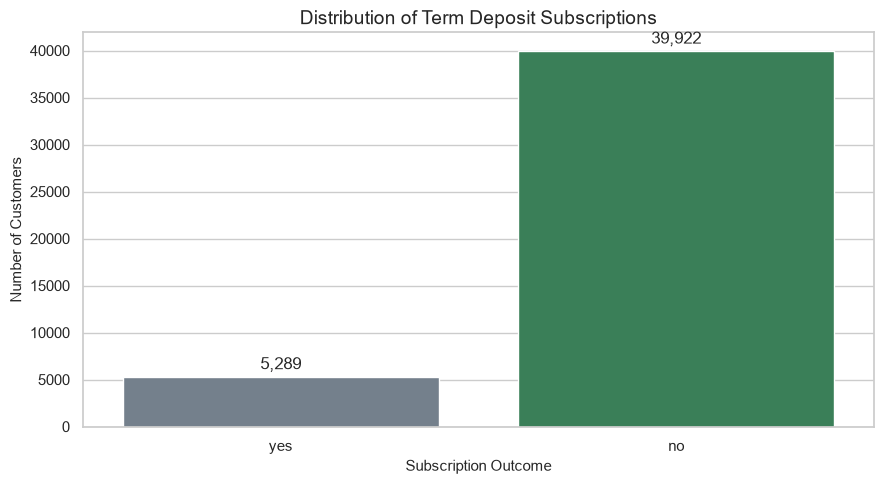

In [40]:
plt.figure(figsize=(9, 5))

ax = sns.countplot(
    data=df_clean,
    x='y',
    hue='y',
    order=['yes', 'no'],
    palette=['#2E8B57', '#708090'],
    legend=False
)

plt.title('Distribution of Term Deposit Subscriptions')
plt.xlabel('Subscription Outcome')
plt.ylabel('Number of Customers')

for container in ax.containers:
    ax.bar_label(container, fmt='{:,.0f}', padding=3)

plt.tight_layout()
plt.show()

In [41]:
subscription_rate = (
    df_clean.groupby('y').size() / total_customers * 100
)

display(
    subscription_rate.rename('Percentage').to_frame()
)

,Percentage
y,
no,88.30
yes,11.70



**Initial Observations**

The overall subscription rate provides a baseline for evaluating campaign effectiveness.

The distribution indicates that the majority of contacted customers did not subscribe to the term deposit. This highlights an opportunity to investigate differences in subscription behaviour across customer segments and campaign interactions.

Further analysis is required to identify segments with comparatively higher subscription rates.


### 7.2 Customer Demographics Analysis

This section investigates subscription behaviour across different customer demographic groups.

The objective is to identify variations in subscription rates across age groups, occupations, marital status, and educational backgrounds.

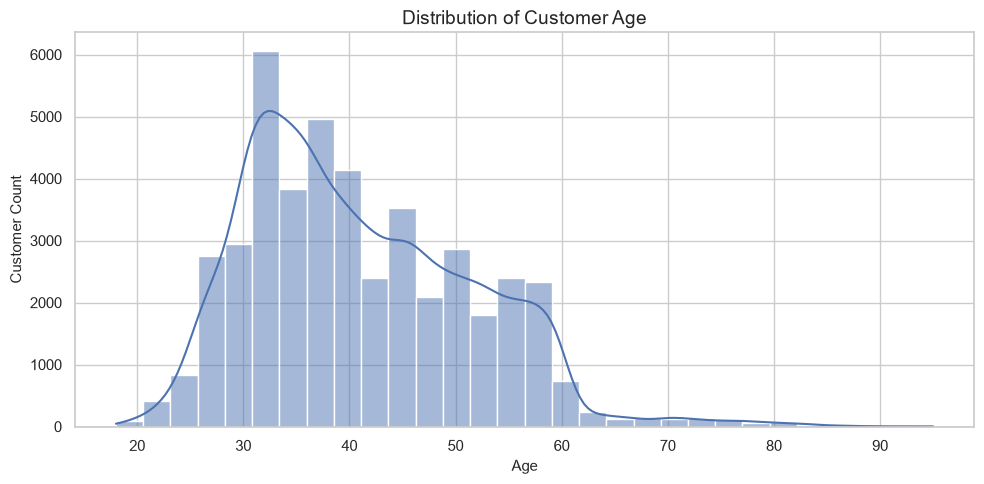

In [42]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x='age',
    bins=30,
    kde=True
)

plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.ylabel('Customer Count')

plt.tight_layout()
plt.show()

In [43]:
df_clean['age_group'] = pd.cut(
    df_clean['age'],
    bins=[0, 25, 35, 45, 55, 65, float('inf')],
    labels=['18-25', '26-35', '36-45',
            '46-55', '56-65', '65+']
)

In [44]:
age_analysis = (
    df_clean.groupby('age_group', observed=True)['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .sort_values(ascending=False)
)

display(
    age_analysis.rename(
        'Subscription Rate (%)'
    ).to_frame()
)

,Subscription Rate (%)
age_group,
65+,42.61
18-25,23.95
56-65,14.12
26-35,12.00
36-45,9.39
46-55,9.35


In [45]:
job_analysis = (
    df_clean.groupby('job')['y']
    .apply(lambda x: (x == 'yes').mean() * 100)
    .sort_values(ascending=False)
)

display(
    job_analysis.rename(
        'Subscription Rate (%)'
    ).to_frame()
)

,Subscription Rate (%)
job,
student,28.68
retired,22.79
unemployed,15.50
management,13.76
admin.,12.20
self-employed,11.84
unknown,11.81
technician,11.06
services,8.88


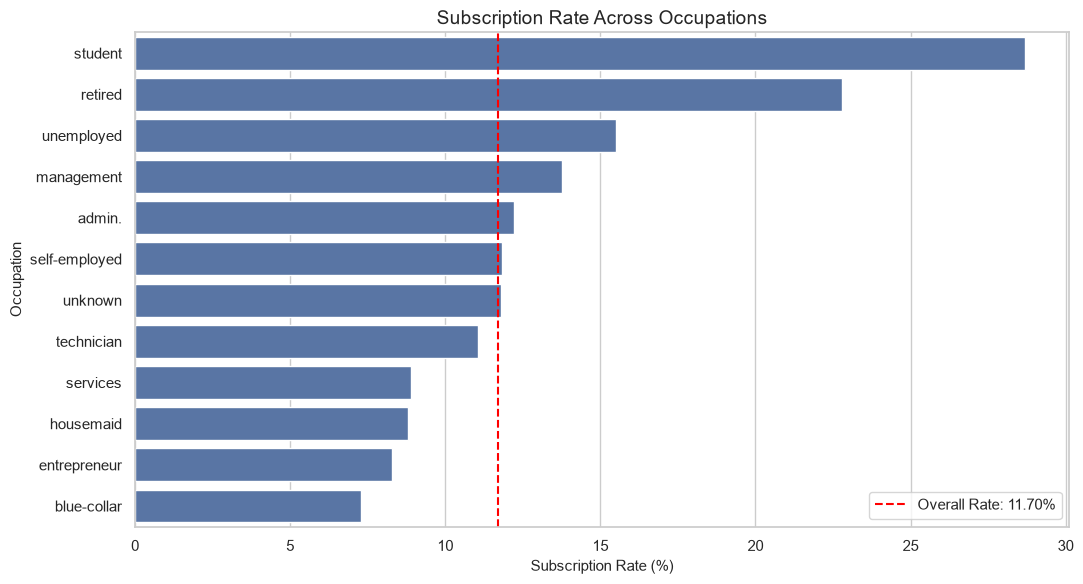

In [46]:
plt.figure(figsize=(11, 6))

sns.barplot(
    x=job_analysis.values,
    y=job_analysis.index
)

plt.axvline(
    conversion_rate,
    linestyle='--',
    color='red',
    label=f'Overall Rate: {conversion_rate:.2f}%'
)

plt.title('Subscription Rate Across Occupations')
plt.xlabel('Subscription Rate (%)')
plt.ylabel('Occupation')
plt.legend()

plt.tight_layout()
plt.show()